In [1]:
%pip install -q "transformers==4.57.1"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import hashlib
import json
import random
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from transformers import AutoProcessor
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

In [4]:
MLLM = Path("/content/drive/MyDrive/MLLM/mordern_llm")
D_ROOT = Path("/content/drive/MyDrive/MLLM/section_d")
D_DATA = D_ROOT / "data"
D_DATA.mkdir(parents=True, exist_ok=True)

C_DATA = MLLM / "data/sroie"
manifest = json.loads((C_DATA / "manifest.json").read_text(encoding="utf-8"))
task = json.loads((C_DATA / "task_config.json").read_text(encoding="utf-8"))

TRAIN = manifest["train"]
FIELDS = tuple(task["fields"])
DOC_PROMPT = task["prompt"]
IMAGE_KWARGS = task["image_kwargs"]

processor = AutoProcessor.from_pretrained(MLLM / "outputs/qlora_run1/best_adapter", use_fast=False)
processor.tokenizer.padding_side = "right"

print("Section C folder:", MLLM)
print("Train / validation:", len(TRAIN), len(manifest["val"]))
print("Fields:", FIELDS)

Section C folder: /content/drive/MyDrive/MLLM/mordern_llm
Train / validation: 551 61
Fields: ('company', 'date', 'total')


In [5]:
LOCK_FILE = D_DATA / "heldout_manifest.json"
LOCAL_TEST_PARQUET = None
N_TEST, SEED = 30, 45

used = manifest["train"] + manifest["val"] + manifest["test"]
used_ids = {r["id"] for r in used}
used_hashes = {r["sha256"] for r in used}

if LOCK_FILE.is_file():
    heldout = json.loads(LOCK_FILE.read_text(encoding="utf-8"))

else:
    source = LOCAL_TEST_PARQUET or hf_hub_download(
        repo_id=manifest["dataset"],
        repo_type="dataset",
        revision=manifest["revision"],
        filename="data/test-00000-of-00001.parquet"
    )
    candidates = pq.read_table(source, columns=["key", "image", "entities"]).to_pylist()
    random.Random(SEED).shuffle(candidates)
    
    selected = []
    seen_ids, seen_hashes = used_ids.copy(), used_hashes.copy()
    
    for row in candidates:
        sample_id = row["key"]
        raw = row["image"]["bytes"]
        reference = {field: row["entities"][field] for field in FIELDS}
        
        if not raw or not all(isinstance(v, str) and v.strip() for v in reference.values()):
            continue
        
        digest = hashlib.sha256(raw).hexdigest()
        if sample_id in seen_ids or digest in seen_hashes:
            continue
        
        rel_path = Path("data/heldout_images") / f"{sample_id}.jpg"
        selected.append((
            {"id": sample_id, "sha256": digest, "reference": reference,
            "image_path": str(rel_path)}, raw
        ))
        seen_ids.add(sample_id)
        seen_hashes.add(digest)

        if len(selected) == N_TEST:
            break

    for record, raw in selected:
        path = D_ROOT / record["image_path"]
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(raw)

    heldout = {
        "dataset": manifest["dataset"],
        "revision": manifest["revision"],
        "seed": SEED,
        "test": [record for record, _ in selected]
    }
    LOCK_FILE.write_text(json.dumps(heldout, ensure_ascii=False, indent=2), encoding="utf-8")

D_TEST = heldout["test"]
print("Locked held-out receipts:", len(D_TEST))
print("Saved:", LOCK_FILE)

Locked held-out receipts: 30
Saved: /content/drive/MyDrive/MLLM/section_d/data/heldout_manifest.json


Receipt ID: X00016469612
Original size: (463, 1013)
Raw reference: {'company': 'BOOK TA .K (TAMAN DAYA) SDN BHD', 'date': '25/12/2018', 'total': '9.00'}

Formatted conversation:

<|im_start|>user
<|vision_start|><|image_pad|><|vision_end|>Extract the issuing company name, receipt date, and final total payable from this receipt. Do not confuse the total with subtotal, tax alone, cash tendered, or change. Preserve the printed date format. Return exactly one JSON object with keys company, date, total. Every value must be a string, or null if not visible. Do not infer missing information. No markdown or explanation.<|im_end|>
<|im_start|>assistant
{"company": "BOOK TA .K (TAMAN DAYA) SDN BHD", "date": "25/12/2018", "total": "9.00"}<|im_end|>



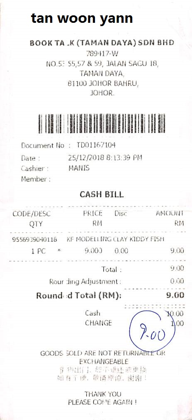

In [6]:
def make_example(record):
    path = Path(record["image_path"])
    if not path.is_file():
        path = MLLM / "images" / path.name
    
    with Image.open(path) as source:
        image = source.convert("RGB")
    
    target = json.dumps(
        {field: record["reference"][field] for field in FIELDS},
        ensure_ascii=False
    )
    
    user = {
        "role": "user",
        "content" : [
            {"type": "image"},
            {"type": "text", "text": DOC_PROMPT}
        ]
    }
    
    assistant = {"role": "assistant", "content": target}
    return {"image": image, "messages": [user, assistant]}


def render(messages, generation_prompt=False):
    return processor.apply_chat_template(
        messages, tokenize=False,
        add_generation_prompt=generation_prompt
    )


example = make_example(TRAIN[0])

print("Receipt ID:", TRAIN[0]["id"])
print("Original size:", example["image"].size)
print("Raw reference:", TRAIN[0]["reference"])
print("\nFormatted conversation:\n")
print(render(example["messages"]))

preview = example["image"].copy()
preview.thumbnail((320, 420))
display(preview)

In [ ]:
def encode(conversations, images, budget, generation_prompt=False):
    return processor(
        text=[render(m, generation_prompt) for m in conversations],
        images=images,
        images_kwargs=budget,
        add_special_tokens=False,
        padding=True,
        truncation=False,
        return_tensors="pt"
    )


merge = processor.image_processor.merge_size
patch = processor.image_processor.patch_size
image_token_id = processor.image_token_id

low_max = min(128 * (patch * merge)**2, IMAGE_KWARGS["max_pixels"])
low_budget = {
    **IMAGE_KWARGS,
    "max_pixels": low_max,
    "min_pixels": min(IMAGE_KWARGS["min_pixels"], low_max)
}

budget_rows = []

for name, budget in [("low", low_budget), ("section_c", IMAGE_KWARGS)]:
    encoded = encode([example["messages"]], [example["image"]], budget)

    grid = encoded["image_grid_thw"][0]
    patch_rows = int(grid.prod())
    slots = int((encoded["input_ids"] == image_token_id).sum())


    budget_rows.append({
        "budget": name,
        "grid_thw": grid.tolist(),
        "patch_rows": patch_rows,
        "visual_slots": slots,
        "sequence_tokens": int(encoded["attention_mask"].sum())
    })

display(pd.DataFrame(budget_rows))

,budget,grid_thw,patch_rows,visual_slots,sequence_tokens
0,low,"[1, 32, 14]",448,112,246
1,section_c,"[1, 64, 28]",1792,448,582


In [9]:
def collate_training(examples, budget=IMAGE_KWARGS):
    prompts, conversations, images = [], [], []
    
    for row in examples:
        if "messages" in row:
            prompt, completion = row["messages"][:-1], row["messages"][-1:]
        else:
            prompt, completion = row["prompt"], row["completion"]

        full = prompt + completion
        assert [m["role"] for m in full] == ["user", "assistant"]

        prompts.append(prompt)
        conversations.append(full)
        images.append(row["image"])

    batch = encode(conversations, images, budget)
    prefix = encode(prompts, images, budget, generation_prompt=True)
    
    ids = batch["input_ids"]
    labels = ids.clone()
    
    for i in range(len(examples)):
        n = int(prefix["attention_mask"][i].sum())
        labels[i, :n] = -100

    labels[batch["attention_mask"] == 0] = -100
    labels[ids == image_token_id] = -100

    batch["labels"] = labels
    return batch

In [10]:
samples = [make_example(TRAIN[0]), make_example(TRAIN[1])]
batch = collate_training(samples)

for key in ["input_ids", "attention_mask", "pixel_values",
            "image_grid_thw", "labels"]:
    print(key, tuple(batch[key].shape), batch[key].dtype)

for i, labels in enumerate(batch["labels"]):
    kept = labels[labels != -100]
    decoded = processor.tokenizer.decode(kept, skip_special_tokens=False)
    clean = processor.tokenizer.decode(kept, skip_special_tokens=True)

    print(f"\nSample {i} | supervised={len(kept)} | "
          f"padding={int((batch['attention_mask'][i] == 0).sum())}")
    print(decoded)

    expected = {field: TRAIN[i]["reference"][field] for field in FIELDS}


prompt_completion = {
    "image": example["image"],
    "prompt": example["messages"][:1],
    "completion": example["messages"][1:]
}

as_messages = collate_training([example])
as_pc = collate_training([prompt_completion])

input_ids (2, 582) torch.int64
attention_mask (2, 582) torch.int64
pixel_values (3528, 1536) torch.float32
image_grid_thw (2, 3) torch.int64
labels (2, 582) torch.int64

Sample 0 | supervised=46 | padding=0
{"company": "BOOK TA .K (TAMAN DAYA) SDN BHD", "date": "25/12/2018", "total": "9.00"}<|im_end|>


Sample 1 | supervised=40 | padding=20
{"company": "INDAH GIFT & HOME DECO", "date": "19/10/2018", "total": "60.30"}<|im_end|>

